# Tarea 4: mínimos de funciones de prueba con Newton y Broyden

Se calculan los mínimos de las funciones de Rastrigin, Ackley, Rosenbrock, Levy, Griewank, Easom y camello de tres jorobas (todas en 2 variables) buscando los ceros del gradiente $\nabla F(\mathbf{x})=0$:

* **Newton** con $f=\nabla F$ y $g=\nabla^2F$ (la Hessiana).
* **Broyden** con $f=\nabla F$.

Después se estima el tamaño de una vecindad del mínimo en la que Newton funciona bien y la velocidad de convergencia de ambos métodos.

In [1]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
import os

# Carpetas de salida (mismas que usa la plantilla de LaTeX)
os.makedirs('tablas', exist_ok=True)
os.makedirs('figuras', exist_ok=True)

def sci(v, d=2):
    # Número en notación científica para LaTeX
    if v == 0:
        return '$0$'
    m, e = f"{v:.{d}e}".split('e')
    return f"${m}\\times10^{{{int(e)}}}$"

def guardar_tabla(nombre, encabezado, filas, alin):
    # Escribe tablas/<nombre>.tex con un tabular (el caption va en el reporte)
    L = ['\\begin{tabular}{' + alin + '}', '\\toprule',
         '\\rowcolor{Azul1!50}', ' & '.join(encabezado) + ' \\\\', '\\midrule']
    L += [' & '.join(f) + ' \\\\' for f in filas]
    L += ['\\bottomrule', '\\end{tabular}']
    with open(f'tablas/{nombre}.tex', 'w', encoding='utf-8') as fh:
        fh.write('\n'.join(L) + '\n')
    print(f'Guardada: tablas/{nombre}.tex')

## 1. Los métodos

Se usaron los códigos del repositorio del curso para los métodos de Newton y Broyden. En `broyden` solo se quitó una asignación de `flag` que se sobrescribía.

In [2]:
def zNewton(f, g, x0, itermax, tol):
    """Método de Newton para f(x)=0 con jacobiano g."""
    x0 = np.asarray(x0, dtype=float).flatten()
    flag = True
    orbita = [x0.copy()]
    iter_count = 1

    xk = x0
    error = 0.0

    while flag and iter_count < itermax:
        fx = np.asarray(f(x0), dtype=float)
        gx = np.asarray(g(x0), dtype=float)

        # Paso sk = -g(x0) \ f(x0)
        if gx.ndim == 0 or gx.size == 1:
            sk = -fx / gx
        else:
            sk = np.linalg.solve(gx, -fx)

        xk = x0 + sk
        error = float(np.linalg.norm(xk - x0))

        norm_x0 = float(np.linalg.norm(x0))
        if norm_x0 > 0 and error < tol * norm_x0:
            flag = False  # paro relativo
        elif norm_x0 == 0 and error < tol:
            flag = False  # paro absoluto si x0 es cero

        orbita.append(xk.copy())
        iter_count += 1
        x0 = xk

    return xk, orbita, error


def broyden(f, x0, itermax, tol):
    """Método de Broyden para f(x)=0 con B0 = I."""
    x0 = np.array(x0, dtype=float)
    n = len(x0)

    flag = 1
    orbita = [x0.copy()]
    iter_cnt = 1
    Bk = np.eye(n)

    xk = x0.copy()
    error = 0.0

    while flag and iter_cnt < itermax:
        fx0 = f(x0)

        sk = np.linalg.solve(Bk, -fx0)
        alpha = 1.0

        xk = x0 + alpha * sk
        yk = f(xk) - fx0

        # Actualización de rango uno
        Bk = Bk + np.outer(yk - Bk @ sk, sk) / np.dot(sk, sk)

        error = np.linalg.norm(xk - x0)
        if error < (np.linalg.norm(x0) + 1) * tol:
            flag = 0

        orbita.append(xk.copy())
        iter_cnt += 1
        x0 = xk.copy()

    return xk, np.array(orbita), error

## 2. Las funciones

Para no cometer errores a mano, el gradiente y la Hessiana se obtienen simbólicamente con `sympy` y se convierten a funciones de NumPy. Después se validan con diferencias finitas.

| Función | Mínimo global $\mathbf{x}^*$ | $F(\mathbf{x}^*)$ |
|---|---|---|
| Rastrigin | $(0,0)$ | $0$ |
| Ackley | $(0,0)$ | $0$ |
| Rosenbrock | $(1,1)$ | $0$ |
| Levy | $(1,1)$ | $0$ |
| Griewank | $(0,0)$ | $0$ |
| Easom | $(\pi,\pi)$ | $-1$ |
| Camello de tres jorobas | $(0,0)$ | $0$ |

**Nota sobre Ackley:** no es diferenciable en el origen (tiene un pico cónico), justo donde está el mínimo. Ahí se toma el gradiente igual a $0$ (que es lo que corresponde a un mínimo); la Hessiana no existe en ese punto.

In [3]:
x, y = sp.symbols('x y', real=True)
pi = sp.pi

expr = {
    'Rastrigin':  20 + x**2 - 10*sp.cos(2*pi*x) + y**2 - 10*sp.cos(2*pi*y),
    'Ackley':     -20*sp.exp(-sp.Rational(1, 5)*sp.sqrt((x**2 + y**2)/2))
                  - sp.exp((sp.cos(2*pi*x) + sp.cos(2*pi*y))/2) + sp.E + 20,
    'Rosenbrock': 100*(y - x**2)**2 + (1 - x)**2,
    'Levy':       (sp.sin(pi*(1 + (x-1)/4))**2
                   + ((x-1)/4)**2*(1 + 10*sp.sin(pi*(1 + (x-1)/4) + 1)**2)
                   + ((y-1)/4)**2*(1 + sp.sin(2*pi*(1 + (y-1)/4))**2)),
    'Griewank':   1 + (x**2 + y**2)/4000 - sp.cos(x)*sp.cos(y/sp.sqrt(2)),
    'Easom':      -sp.cos(x)*sp.cos(y)*sp.exp(-((x - pi)**2 + (y - pi)**2)),
    'Camello':    2*x**2 - sp.Rational(21, 20)*x**4 + x**6/6 + x*y + y**2,
}

xmin = {'Rastrigin': (0, 0), 'Ackley': (0, 0), 'Rosenbrock': (1, 1), 'Levy': (1, 1),
        'Griewank': (0, 0), 'Easom': (np.pi, np.pi), 'Camello': (0, 0)}

F, gradF, hessF = {}, {}, {}
for nombre, e in expr.items():
    F_ = sp.lambdify((x, y), e, 'numpy')
    g_ = sp.lambdify((x, y), [sp.diff(e, x), sp.diff(e, y)], 'numpy')
    H_ = sp.lambdify((x, y), sp.hessian(e, (x, y)), 'numpy')
    F[nombre]     = lambda X, F_=F_: float(F_(X[0], X[1]))
    gradF[nombre] = lambda X, g_=g_: np.array(g_(X[0], X[1]), dtype=float)
    hessF[nombre] = lambda X, H_=H_: np.array(H_(X[0], X[1]), dtype=float)

# Ackley en el origen: el gradiente se define como 0 (mínimo del pico cónico)
_g, _H = gradF['Ackley'], hessF['Ackley']
gradF['Ackley'] = lambda X: np.zeros(2) if np.linalg.norm(X) == 0 else _g(X)

### Validación con diferencias finitas

Se compara el gradiente y la Hessiana simbólicos con diferencias centrales en un punto fijo.

In [4]:
def dif_fin_grad(fun, X, h=1e-6):
    return np.array([(fun(X + h*e) - fun(X - h*e)) / (2*h) for e in np.eye(2)])

def dif_fin_hess(grad, X, h=1e-5):
    return np.array([(grad(X + h*e) - grad(X - h*e)) / (2*h) for e in np.eye(2)])

P = np.array([0.37, -0.52])
print(f"{'Función':<12}{'err. gradiente':>16}{'err. Hessiana':>16}")
for nombre in expr:
    eg = np.linalg.norm(gradF[nombre](P) - dif_fin_grad(F[nombre], P))
    eH = np.linalg.norm(hessF[nombre](P) - dif_fin_hess(gradF[nombre], P))
    print(f"{nombre:<12}{eg:>16.2e}{eH:>16.2e}")

Función       err. gradiente   err. Hessiana
Rastrigin           2.25e-09        3.14e-07
Ackley              1.44e-09        3.63e-09
Rosenbrock          8.02e-09        4.10e-08
Levy                1.11e-10        2.33e-10
Griewank            2.51e-11        1.36e-11
Easom               6.47e-19        3.31e-17
Camello             4.01e-11        2.79e-10


## 3. Cálculo de los mínimos

Se parte de un punto cercano al mínimo, $\mathbf{x}_0=\mathbf{x}^*+(0.1,\,0.1)$, con tolerancia $10^{-10}$ y a lo más 100 iteraciones. Se reporta la solución, el número de iteraciones y la norma del gradiente final. Se considera que un método *acierta* si termina a menos de $10^{-6}$ de $\mathbf{x}^*$.

In [5]:
TOL, ITERMAX = 1e-10, 100

def resolver(metodo, nombre, x0):
    """Corre Newton o Broyden sobre grad F. Devuelve (xk, orbita) o None si falla."""
    with np.errstate(all='ignore'):
        try:
            if metodo == 'Newton':
                xk, orb, _ = zNewton(gradF[nombre], hessF[nombre], x0, ITERMAX, TOL)
            else:
                xk, orb, _ = broyden(gradF[nombre], x0, ITERMAX, TOL)
        except np.linalg.LinAlgError:
            return None
    orb = np.array(orb, dtype=float)
    if not np.all(np.isfinite(orb)):
        return None
    return xk, orb

def acierta(nombre, xk):
    return np.linalg.norm(xk - np.array(xmin[nombre])) < 1e-6

def num(v):
    """Número para LaTeX: notación científica si es muy pequeño."""
    if v == 0 or abs(v) >= 1e-4:
        return f"{v:.6g}"
    m, e = f"{v:.2e}".split('e')
    return f"{m}\\times10^{{{int(e)}}}"

filas_min = []
print(f"{'Función':<11}{'Método':<8}{'Solución':<34}{'Iter':>5}{'‖∇F‖':>11}{'Acierta':>9}")
for nombre in expr:
    x0 = np.array(xmin[nombre]) + 0.1
    for metodo in ['Newton', 'Broyden']:
        res = resolver(metodo, nombre, x0)
        if res is None:
            print(f"{nombre:<11}{metodo:<8}{'falla':<34}")
            filas_min.append([f"\\texttt{{{nombre}}}", metodo, 'falla', '---', '---', 'No'])
            continue
        xk, orb = res
        gn = np.linalg.norm(gradF[nombre](xk))
        print(f"{nombre:<11}{metodo:<8}{str(xk):<34}{len(orb):>5}"
              f"{gn:>11.1e}{str(acierta(nombre, xk)):>9}")
        filas_min.append([f"\\texttt{{{nombre}}}", metodo,
                          "$(" + num(xk[0]) + ",\\," + num(xk[1]) + ")$", str(len(orb)), sci(gn),
                          'Sí' if acierta(nombre, xk) else 'No'])

guardar_tabla('t4_minimos', ['Función', 'Método', 'Solución', 'Iter.', r'$\|\nabla F\|$', 'Acierta'],
              filas_min, 'l l l r r c')

Función    Método  Solución                           Iter       ‖∇F‖  Acierta
Rastrigin  Newton  [0. 0.]                               6    0.0e+00     True
Rastrigin  Broyden [ 23.81317317 -27.63730123]         100    1.3e+01    False
Ackley     Newton  [-0.67309652 -0.67309652]             9    3.1e-16    False
Ackley     Broyden [15801.5 16447. ]                    93    3.1e-11    False
Rosenbrock Newton  [1. 1.]                               7    0.0e+00     True
Rosenbrock Broyden [1.61936534 2.62241034]             100    1.2e+00    False
Levy       Newton  [1. 1.]                               5    4.2e-16     True
Levy       Broyden [1. 1.]                              12    5.2e-17     True
Griewank   Newton  [ 0.00000000e+000 -1.20495993e-181]   14    0.0e+00     True
Griewank   Broyden [-2.80395773e-24 -3.40606055e-22]     8    1.7e-22     True
Easom      Newton  [3.14159265 3.14159265]               5    1.7e-16     True
Easom      Broyden [3.14159265 3.14159265]         

### ¿En qué tipo de punto terminan las corridas que no aciertan?

Newton y Broyden resuelven $\nabla F=0$, y esa ecuación también se cumple en máximos y puntos silla. Para las corridas que no llegan a $\mathbf{x}^*$ pero terminan con gradiente casi nulo, se clasifica el punto con los valores propios de la Hessiana: todos positivos es un mínimo, todos negativos un máximo y de distinto signo un punto silla.

In [6]:
for nombre in expr:
    x0 = np.array(xmin[nombre]) + 0.1
    for metodo in ['Newton', 'Broyden']:
        res = resolver(metodo, nombre, x0)
        if res is None or acierta(nombre, res[0]):
            continue
        xk = res[0]
        gn = np.linalg.norm(gradF[nombre](xk))
        if gn > 1e-3:
            print(f"{nombre:<11}{metodo:<8} no es punto crítico (‖∇F‖ = {gn:.2e})")
            continue
        with np.errstate(all='ignore'):
            w = np.linalg.eigvalsh(hessF[nombre](xk))
        tipo = 'mínimo' if np.all(w > 0) else 'máximo' if np.all(w < 0) else 'punto silla'
        print(f"{nombre:<11}{metodo:<8} {tipo:<12} F = {F[nombre](xk):<10.4g} valores propios de H: {np.round(w, 3)}")

Rastrigin  Broyden  no es punto crítico (‖∇F‖ = 1.28e+01)
Ackley     Newton   máximo       F = 4.609      valores propios de H: [-15.839  -3.166]
Ackley     Broyden  punto silla  F = 21.72      valores propios de H: [-19.739  19.739]
Rosenbrock Broyden  no es punto crítico (‖∇F‖ = 1.20e+00)


## 4. Vecindad donde Newton funciona "bien"

Para cada función se toman puntos iniciales $\mathbf{x}_0=\mathbf{x}^*+r\,(\cos\theta,\sin\theta)$ con 36 ángulos $\theta$ equiespaciados y radios $r=0.01,0.02,\dots,3$. Newton funciona *bien* en un punto inicial si converge a $\mathbf{x}^*$ (a menos de $10^{-6}$) en a lo más 100 iteraciones.

El tamaño de la vecindad, $r_{\max}$, es el mayor radio tal que **todos** los puntos iniciales (en todas las direcciones) de radio $\le r_{\max}$ funcionan bien. Es una estimación conservadora: pueden existir puntos buenos más lejos, pero ya no con garantía en todas las direcciones.

In [7]:
angulos = np.linspace(0, 2*np.pi, 36, endpoint=False)
radios = np.round(np.arange(0.01, 3.0001, 0.01), 2)

def funciona(metodo, nombre, x0):
    res = resolver(metodo, nombre, x0)
    return res is not None and acierta(nombre, res[0])

def radio_vecindad(nombre, metodo='Newton'):
    xs = np.array(xmin[nombre])
    for r in radios:
        for th in angulos:
            if not funciona(metodo, nombre, xs + r*np.array([np.cos(th), np.sin(th)])):
                return round(r - 0.01, 2), r, th      # último radio bueno, primer fallo
    return radios[-1], None, None

rmax = {}
filas_rmax = []
print(f"{'Función':<12}{'r_max':>7}   Primer fallo")
for nombre in expr:
    r_ok, r_mal, th = radio_vecindad(nombre)
    rmax[nombre] = r_ok
    detalle = '(ninguno hasta r = 3)' if r_mal is None else f"r = {r_mal}, θ = {np.degrees(th):.0f}°"
    print(f"{nombre:<12}{r_ok:>7.2f}   {detalle}")
    if r_mal is None:
        filas_rmax.append([f"\\texttt{{{nombre}}}", f"$\\ge {r_ok:.2f}$", 'ninguno hasta $r=3$'])
    else:
        filas_rmax.append([f"\\texttt{{{nombre}}}", f"${r_ok:.2f}$",
                           f"$r={r_mal:.2f}$, $\\theta={np.degrees(th):.0f}^\\circ$"])

guardar_tabla('t4_vecindad', ['Función', r'$r_{\max}$', 'Primer fallo'], filas_rmax, 'l c l')

Función       r_max   Primer fallo
Rastrigin      0.18   r = 0.19, θ = 0°
Ackley         0.00   r = 0.01, θ = 0°
Rosenbrock     3.00   (ninguno hasta r = 3)
Levy           0.49   r = 0.5, θ = 180°
Griewank       0.95   r = 0.96, θ = 30°
Easom          0.41   r = 0.42, θ = 20°
Camello        0.42   r = 0.43, θ = 0°
Guardada: tablas/t4_vecindad.tex


Camello        0.42   r = 0.43, θ = 0°
Guardada: tablas/t4_vecindad.tex


Como complemento, el porcentaje de puntos iniciales que funcionan a distintos radios (más allá de $r_{\max}$ el éxito ya no es total, pero puede ser parcial).

In [8]:
radios_tabla = [0.05, 0.1, 0.25, 0.5, 1.0, 2.0]
print(f"{'Función':<12}" + "".join(f"{'r='+str(r):>9}" for r in radios_tabla))
filas_exito = []
for nombre in expr:
    xs = np.array(xmin[nombre])
    fila, fila_tex = [], [f"\\texttt{{{nombre}}}"]
    for r in radios_tabla:
        ok = sum(funciona('Newton', nombre, xs + r*np.array([np.cos(t), np.sin(t)])) for t in angulos)
        fila.append(f"{100*ok/len(angulos):>8.0f}%")
        fila_tex.append(f"{100*ok/len(angulos):.0f}\\,\\%")
    print(f"{nombre:<12}" + "".join(fila))
    filas_exito.append(fila_tex)

guardar_tabla('t4_exito', ['Función'] + [f'$r={r}$' for r in radios_tabla], filas_exito,
              'l' + ' r' * len(radios_tabla))

Función        r=0.05    r=0.1   r=0.25    r=0.5    r=1.0    r=2.0
Rastrigin        100%     100%       0%       0%       0%       0%
Ackley             0%       0%       0%       0%       0%       0%
Rosenbrock       100%     100%     100%     100%     100%     100%
Levy             100%     100%     100%      97%      17%      31%
Griewank         100%     100%     100%     100%      67%       0%
Easom            100%     100%     100%       0%       0%       0%
Camello          100%     100%     100%      61%      28%      17%
Guardada: tablas/t4_exito.tex


Para ver cómo cambia el éxito con la distancia, se repite el cálculo con una malla de radios más fina ($r=0.02,0.04,\dots,3$) y se grafica el porcentaje de puntos iniciales (36 direcciones) con los que Newton converge a $\mathbf{x}^*$, una curva por función.

Guardada: figuras/t4_vecindad.pdf


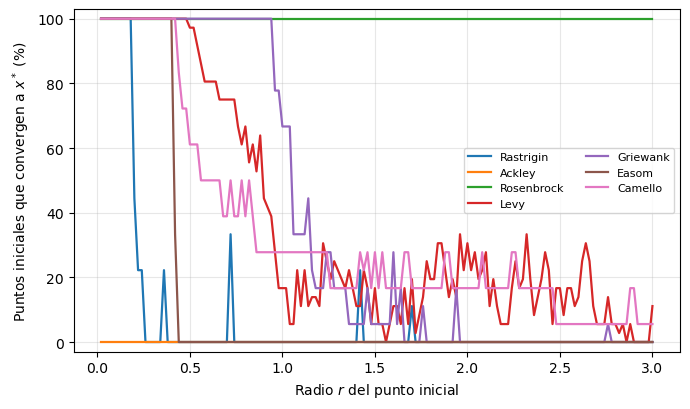

In [9]:
radios_fino = np.round(np.arange(0.02, 3.0001, 0.02), 2)

exito = {}
for nombre in expr:
    xs = np.array(xmin[nombre])
    exito[nombre] = [100*sum(funciona('Newton', nombre, xs + r*np.array([np.cos(t), np.sin(t)]))
                             for t in angulos)/len(angulos) for r in radios_fino]

fig, ax = plt.subplots(figsize=(7, 4.2))
for nombre in expr:
    ax.plot(radios_fino, exito[nombre], lw=1.6, label=nombre)
ax.set_xlabel(r'Radio $r$ del punto inicial')
ax.set_ylabel('Puntos iniciales que convergen a $x^*$ (%)')
ax.set_ylim(-3, 103)
ax.grid(alpha=0.3); ax.legend(loc='center right', ncol=2, fontsize=8)
fig.tight_layout()
fig.savefig('figuras/t4_vecindad.pdf', bbox_inches='tight')
print('Guardada: figuras/t4_vecindad.pdf')
plt.show()

## 5. Velocidad de convergencia

Con la órbita se calcula el error $e_k=\lVert\mathbf{x}_k-\mathbf{x}^*\rVert$ y el orden de convergencia estimado
$$
p_k=\frac{\ln(e_{k+1}/e_k)}{\ln(e_k/e_{k-1})}.
$$
Se usan solo los errores mayores que $10^{-13}$ para no medir ruido de redondeo. Como la convergencia es muy rápida, quedan pocos valores por corrida, así que se imprimen todos los $p_k$ y no solo el último. Para Broyden se imprimen también los cocientes $e_{k+1}/e_k$: si la convergencia es superlineal, tienden a 0.

Lo esperado es $p\approx2$ en Newton y superlineal ($p\approx1.6$) en Broyden. El punto inicial es el mismo de la sección 3, $\mathbf{x}^*+(0.1,0.1)$.

In [10]:
def errores(nombre, orb):
    e = np.linalg.norm(orb - np.array(xmin[nombre]), axis=1)
    return e[e > 1e-13]          # descarta ruido de redondeo

def ordenes(e):
    """Lista de p_k para k = 1, ..., len(e)-2."""
    return [np.log(e[k+1]/e[k]) / np.log(e[k]/e[k-1]) for k in range(1, len(e)-1)]

errs = {}
filas_ord = []
for nombre in expr:
    x0 = np.array(xmin[nombre]) + 0.1
    for metodo in ['Newton', 'Broyden']:
        res = resolver(metodo, nombre, x0)
        if res is None:
            print(f"{nombre:<11}{metodo:<8} falla")
            filas_ord.append([f"\\texttt{{{nombre}}}", metodo, '---', '---', '---'])
            continue
        xk, orb = res
        e = errores(nombre, orb)
        errs[(nombre, metodo)] = e
        if not acierta(nombre, xk):
            print(f"{nombre:<11}{metodo:<8} no llega al mínimo global (no se estima p)")
            filas_ord.append([f"\\texttt{{{nombre}}}", metodo, str(len(orb)), 'no llega a $\\mathbf{x}^*$', '---'])
            continue
        p = ordenes(e)
        cocientes = e[1:]/e[:-1]
        filas_ord.append([f"\\texttt{{{nombre}}}", metodo, str(len(orb)),
                          '$' + ',\\,'.join(f'{v:.2f}' for v in p) + '$' if p else '---',
                          sci(cocientes[-1])])
        print(f"{nombre:<11}{metodo:<8} p_k = {np.round(p, 2)}")
        if metodo == 'Broyden':
            print(f"{'':<19} e_(k+1)/e_k = {np.array2string(cocientes, precision=2)}")

guardar_tabla('t4_orden', ['Función', 'Método', 'Iter.', r'$p_k$', r'$e_{k+1}/e_k$ (último)'],
              filas_ord, 'l l r l r')

Rastrigin  Newton   p_k = [3.09 3.  ]
Rastrigin  Broyden  no llega al mínimo global (no se estima p)
Ackley     Newton   no llega al mínimo global (no se estima p)
Ackley     Broyden  no llega al mínimo global (no se estima p)
Rosenbrock Newton   p_k = [-7.26  0.85  3.31]
Rosenbrock Broyden  no llega al mínimo global (no se estima p)
Levy       Newton   p_k = [2.45 1.82]
Levy       Broyden  p_k = [-5.03  0.22  1.73  2.65 10.24  0.17  0.28 25.32]
                    e_(k+1)/e_k = [1.14e+00 5.07e-01 8.62e-01 7.74e-01 5.07e-01 9.45e-04 3.01e-01 7.10e-01
 1.74e-04]
Griewank   Newton   p_k = [3.03]
Griewank   Broyden  p_k = [0.79 6.16 1.1  1.45]
                    e_(k+1)/e_k = [3.55e-01 4.42e-01 6.51e-03 3.90e-03 3.27e-04]
Easom      Newton   p_k = [3.02]
Easom      Broyden  p_k = [-5.57  0.6   4.45]
                    e_(k+1)/e_k = [1.91e+00 2.68e-02 1.15e-01 6.72e-05]
Camello    Newton   p_k = [2.83]
Camello    Broyden  p_k = [-3.31  0.15  4.38  1.11  3.4 ]
                    e_(k+1)/

### Error contra iteración

Si $p=2$ las curvas de Newton caen cada vez más rápido (la pendiente en escala log se duplica en cada paso).

Guardada: figuras/t4_convergencia.pdf


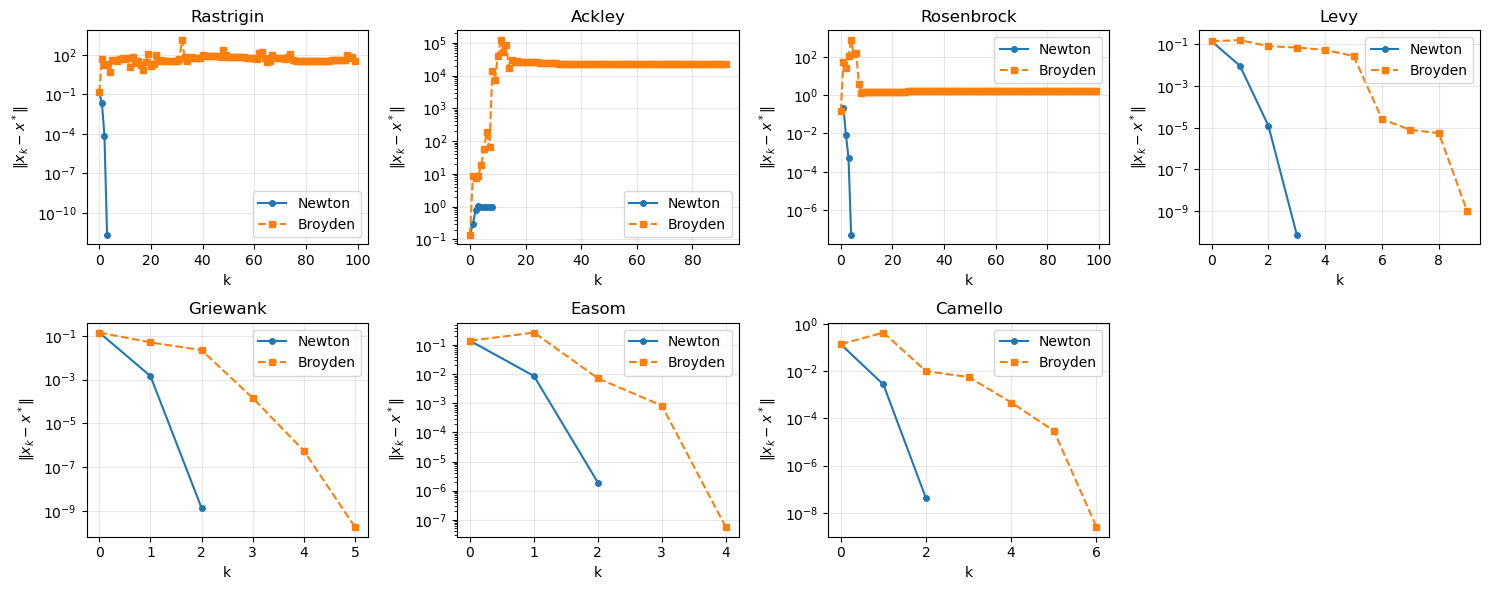

Guardadas: figuras/t4_conv_<función>.pdf (una por función)


In [11]:
def grafica(ax, nombre):
    for metodo, estilo in [('Newton', 'o-'), ('Broyden', 's--')]:
        if (nombre, metodo) in errs:
            ax.semilogy(errs[(nombre, metodo)], estilo, ms=4, label=metodo)
    ax.set_title(nombre); ax.set_xlabel('k'); ax.set_ylabel(r'$\|x_k-x^*\|$')
    ax.grid(alpha=0.3); ax.legend()

# Figura conjunta (para ver en la notebook y como respaldo)
fig, axs = plt.subplots(2, 4, figsize=(15, 6))
for ax, nombre in zip(axs.flat, expr):
    grafica(ax, nombre)
axs.flat[-1].axis('off')
plt.tight_layout()
plt.savefig('figuras/t4_convergencia.pdf', bbox_inches='tight')
print('Guardada: figuras/t4_convergencia.pdf')
plt.show()

# Una figura por función (más grandes, para armar paneles en el reporte)
for nombre in expr:
    fig, ax = plt.subplots(figsize=(5, 3.8))
    grafica(ax, nombre)
    fig.tight_layout()
    fig.savefig(f'figuras/t4_conv_{nombre}.pdf', bbox_inches='tight')
    plt.close(fig)
print('Guardadas: figuras/t4_conv_<función>.pdf (una por función)')

### Datos adicionales para el análisis

Para explicar por qué los métodos aciertan o fallan se calculan, desde $\mathbf{x}_0=\mathbf{x}^*+(0.1,0.1)$ (a distancia $0.141$ de $\mathbf{x}^*$):

* $\|\nabla F(\mathbf{x}_0)\|$, que es el tamaño del primer paso de Broyden, porque con $B_0=I$ el paso es $-\nabla F(\mathbf{x}_0)$;
* $\|\mathbf{s}_0\|$, el tamaño del primer paso de Newton;
* $r_H$, el primer radio (en las 36 direcciones) donde la Hessiana deja de ser definida positiva.

In [12]:
filas_pasos = []
print(f"{'Función':<11}{'‖∇F(x0)‖':>11}{'‖s0‖ Newton':>13}{'r_H':>7}{'r_max':>7}")
for nombre in expr:
    xs = np.array(xmin[nombre]); x0 = xs + 0.1
    g0 = np.linalg.norm(gradF[nombre](x0))
    with np.errstate(all='ignore'):
        s0 = np.linalg.norm(np.linalg.solve(hessF[nombre](x0), -gradF[nombre](x0)))
        rH = None
        for r in np.arange(0.01, 3.0001, 0.01):
            if any(not np.all(np.linalg.eigvalsh(hessF[nombre](xs + r*np.array([np.cos(t), np.sin(t)]))) > 0)
                   for t in angulos):
                rH = round(r, 2)
                break
    rH_txt = '>3' if rH is None else f"{rH:.2f}"
    print(f"{nombre:<11}{g0:>11.3g}{s0:>13.3g}{rH_txt:>7}{rmax[nombre]:>7.2f}")
    filas_pasos.append([f"\\texttt{{{nombre}}}", f"${g0:.3g}$", f"${s0:.3g}$",
                        '$>3$' if rH is None else f"${rH:.2f}$",
                        '$\\ge3$' if rmax[nombre] >= 3 else f"${rmax[nombre]:.2f}$"])

guardar_tabla('t4_pasos', ['Función', r'$\|\nabla F(\mathbf{x}_0)\|$', r'$\|\mathbf{s}_0\|$ (Newton)', r'$r_H$', r'$r_{\max}$'],
              filas_pasos, 'l r r r r')

Función       ‖∇F(x0)‖  ‖s0‖ Newton    r_H  r_max
Rastrigin         52.5        0.163   0.26   0.18
Ackley            8.64        0.429   0.19   0.00
Rosenbrock        53.3        0.101   0.01   3.00
Levy             0.237        0.132   0.77   0.49
Griewank         0.111        0.143   1.29   0.95
Easom            0.412         0.15   0.59   0.41
Camello           0.58        0.142   0.57   0.42
Guardada: tablas/t4_pasos.tex


## 6. Conclusiones

**Mínimos.** Newton, partiendo de $\mathbf{x}^*+(0.1,0.1)$, llega al mínimo global en 6 de las 7 funciones. En Ackley llega a $(-0.673,-0.673)$, otro punto crítico: el mínimo está en un pico cónico donde la Hessiana no existe. Broyden (con $B_0=I$ y sin búsqueda de paso) llega en 4 de 7 (Levy, Griewank, Easom y camello); en Rastrigin, Ackley y Rosenbrock se va a otro punto o no converge en 100 iteraciones, porque su Hessiana está muy lejos de la identidad (en Rastrigin, $\nabla^2F(\mathbf{x}^*)=\mathrm{diag}(2+40\pi^2)\approx 397\,I$).

**Vecindad de Newton.** El radio $r_{\max}$ (todas las direcciones, a lo más 100 iteraciones) es aproximadamente:

| Función | $r_{\max}$ |
|---|---|
| Rastrigin | 0.18 |
| Ackley | 0 (falla incluso con $r=0.01$) |
| Rosenbrock | $\ge 3$ (todo el rango probado) |
| Levy | 0.49 |
| Griewank | 0.95 |
| Easom | 0.41 |
| Camello | 0.42 |

Las funciones con muchos mínimos locales (Rastrigin) tienen vecindades chicas, del tamaño de un medio período del coseno. Rosenbrock es el mejor caso: su gradiente es un polinomio de grado 3 y Newton converge desde todo el rango probado.

**Velocidad.** En Newton, $p\approx3$ en Rastrigin, Griewank, Easom y camello, y $p\approx2$ (1.8) en Levy; en Rosenbrock las estimaciones son erráticas. Esto es coherente con la teoría: si $F(\mathbf{x}^*+\mathbf{h})=F(\mathbf{x}^*-\mathbf{h})$ (cuatro de estas funciones lo cumplen), el término cuadrático del error de Newton se anula y la convergencia es cúbica; en general es cuadrática. En Broyden, los cocientes $e_{k+1}/e_k$ terminan en $10^{-4}$ a $10^{-5}$ (Levy, Griewank, Easom, camello), lo que indica convergencia superlineal. Los $p_k$ individuales de Broyden son muy ruidosos porque cada corrida tiene solo de 3 a 8 errores utilizables antes de llegar a la precisión de máquina, así que no se reporta un valor único.